## Stellar transient populations

- Done in the context of the merging binary black hole population

In [1]:
pwd

'/home/users/a/aguetar1/Posydon_Data/Tutorial_Notebooks'

In [2]:
# Control if the right python environment is selected (HAS TO BE IN THE POSYDON_ENV !!!)
import sys
print(sys.executable)

/home/users/a/aguetar1/.conda/envs/posydon_env/bin/python


In [3]:
import posydon

print("POSYDON version :", posydon.__version__)

import pandas as pd 

print("pandas version :", pd.__version__)

import numpy as np

print("numpy version :", np.__version__)

POSYDON version : 2.1.1
pandas version : 2.2.3
numpy version : 1.26.4


### 1. Creating multi-metallicity populations

We will select the subset of the population that ends in a binary black hole merger in the 8000 binaries created in the Large-scale population synthesis on HPC facilities. 

In [4]:
from posydon.popsyn.synthetic_population import Population

#### 1.1 Binaries at $Z_{\odot}$

- Conditions are that the properties <b style="color:orange;">S1_state</b> and 
<b style="color:orange;">S2_state</b> = ‘BH’, while the binary has the event == 'CO_contact'.

In [5]:
# Change the path to $PATH_TO_POSYDON_DATA/tutorial_populations/1e+00_Zsun_population.h5
# when using the example population file.
pop1= Population('../Generated_Tuto_Data/1e+00_Zsun_population.h5')
tmp_data = pop1.history.select(columns=['S1_state', 'S2_state', 'event'])

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [6]:
# Selection of S1 being a BH
S1_state = tmp_data['S1_state'] == 'BH'
# Selection of S2 being a BH
S2_state = tmp_data['S2_state'] == 'BH'
# Selection of the binary system being in contact during the double CO phase.
state = tmp_data['event'] == 'CO_contact'

# get the indices of all systems
indices = tmp_data.index

# delete the temporary data
del tmp_data

# get a mask for the indices that satisfy all the conditions
mask = S1_state & S2_state & state

# get the indices that satisfy all the conditions
selected_indices = indices[mask].to_list()

In [7]:
print(selected_indices)
pop1.history[selected_indices]

[380]


,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
380,detached,ZAMS,0.000000e+00,6.316024e+01,0.000000,NaN,initial_cond,0.000000,H-rich_Core_H_burning,29.830218,...,NaN,NaN,NaN,NaN,0.715500,2.703000e-01,NaN,NaN,NaN,NaN
380,detached,CC1,6.924045e+06,1.491706e+02,0.000000,-99.000000,step_HMS_HMS,0.147928,stripped_He_Core_C_depleted,10.262995,...,0.341316,0.026509,0.286132,0.010963,0.035856,9.372818e-01,6.949276e-01,0.271629,0.028521,0.370167
380,detached,NaN,6.924045e+06,9.873719e+01,0.358690,NaN,step_SN,0.000493,BH,7.992721,...,0.341316,0.026509,0.286132,0.010963,0.035856,9.372818e-01,6.949276e-01,0.271629,0.028521,0.370167
380,RLO2,oRLO2,7.103034e+06,5.455507e+01,0.000000,NaN,step_detached,0.581600,BH,7.992721,...,10.042956,NaN,0.000000,0.000000,0.000000,9.861585e-01,7.154997e-01,0.270271,0.317649,1.484921
380,RLO2,oCE2,7.103890e+06,4.586116e+01,0.000000,-2.500999,step_CO_HMS_RLO,0.057977,BH,7.993033,...,10.061018,0.684961,0.000000,0.000000,0.000000,9.861360e-01,7.148022e-01,0.271248,0.640891,2.167808
380,detached,NaN,7.103890e+06,1.952970e-01,0.000000,NaN,step_CE,0.000163,BH,7.993033,...,10.061018,0.684961,0.000000,0.000000,0.000000,9.861360e-01,1.000000e-02,0.975800,NaN,NaN
380,detached,CC2,7.743457e+06,2.783614e-01,0.000000,-97.400110,step_CO_HeMS,1.589405,BH,7.993033,...,6.494748,0.503271,5.333888,0.095759,0.000000,1.043499e-12,5.883617e-25,0.563688,0.347974,0.490568
380,detached,NaN,7.743457e+06,3.589656e-01,0.124703,NaN,step_SN,0.000548,BH,7.993033,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.271424
380,contact,CO_contact,2.654707e+08,1.128013e-08,0.000000,NaN,step_dco,0.769453,BH,7.993033,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.271424


- If your selected indices are empty, no BBH mergers occurred in your population

#### 1.2 Binaries at $2 Z_{\odot}$

In [8]:
pop2 = Population('../Generated_Tuto_Data/2e+00_Zsun_population.h5')

tmp_data2 = pop2.history.select(columns=['S1_state', 'S2_state', 'event'])

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [9]:
# Selection of S1 being a BH
S1_state2 = tmp_data2['S1_state'] == 'BH'
# Selection of S2 being a BH
S2_state2 = tmp_data2['S2_state'] == 'BH'
# Selection of the binary system being in contact during the double CO phase.
state2 = tmp_data2['event'] == 'CO_contact'

# get the indices of all systems
indices2 = tmp_data2.index

# delete the temporary data
del tmp_data2

# get a mask for the indices that satisfy all the conditions
mask2 = S1_state2 & S2_state2 & state2

# get the indices that satisfy all the conditions
selected_indices2 = indices2[mask2].to_list()


print(selected_indices2)
pop2.history[selected_indices2]

[503, 759, 956]


,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
503,detached,ZAMS,0.000000e+00,1.970656e+00,0.000000,NaN,initial_cond,0.000000,H-rich_Core_H_burning,57.165409,...,NaN,NaN,NaN,NaN,6.801000e-01,2.915000e-01,NaN,NaN,NaN,NaN
503,detached,CC1,4.670003e+06,4.077787e+01,0.000000,-99.000000,step_HMS_HMS,0.289255,stripped_He_Core_C_depleted,8.861416,...,9.411801,0.695885,7.081252e+00,2.474113e-01,0.000000e+00,3.312027e-10,3.669147e-100,0.325203,0.025414,0.201011
503,detached,NaN,4.670003e+06,3.281863e+01,0.952933,NaN,step_SN,0.000560,BH,5.241513,...,9.411801,0.695885,7.081252e+00,2.474113e-01,0.000000e+00,3.312027e-10,3.669147e-100,0.325203,0.025414,0.201011
503,detached,CC2,4.676062e+06,3.295720e+01,0.952933,NaN,step_detached,3.217504,BH,5.241513,...,9.457735,NaN,8.427068e+00,1.228292e-01,0.000000e+00,3.463669e-13,1.000000e-99,0.280574,0.031414,0.125176
503,detached,NaN,4.676062e+06,9.990121e+01,0.997973,NaN,step_SN,0.008933,BH,5.241513,...,NaN,NaN,8.427068e+00,NaN,NaN,NaN,NaN,NaN,NaN,0.074852
503,contact,CO_contact,9.424627e+06,1.184795e-08,0.000000,NaN,step_dco,0.865933,BH,5.241513,...,NaN,NaN,8.427068e+00,NaN,NaN,NaN,NaN,NaN,NaN,0.074852
503,contact,END,9.424627e+06,1.184795e-08,0.000000,NaN,step_end,0.000044,BH,5.241513,...,NaN,NaN,8.427068e+00,NaN,NaN,NaN,NaN,NaN,NaN,0.074852
759,detached,ZAMS,0.000000e+00,6.289496e+00,0.000000,NaN,initial_cond,0.000000,H-rich_Core_H_burning,69.596811,...,NaN,NaN,NaN,NaN,6.801000e-01,2.915000e-01,NaN,NaN,NaN,NaN
759,detached,CC1,4.091823e+06,4.049077e+01,0.000000,-99.000000,step_HMS_HMS,0.105449,stripped_He_Core_C_depleted,9.635911,...,0.000000,0.000000,0.000000e+00,0.000000e+00,1.705000e-01,8.017828e-01,6.798627e-01,0.291748,0.018215,0.608863


#### 1.3 Looping over a range of metallicities

In [12]:
# The names of the populations, if you followed along.
files = ['../Generated_Tuto_Data/1e-01_Zsun_population.h5',
         '../Generated_Tuto_Data/1e-02_Zsun_population.h5',
         '../Generated_Tuto_Data/1e-03_Zsun_population.h5',
         '../Generated_Tuto_Data/1e+00_Zsun_population.h5',
         '../Generated_Tuto_Data/2e-01_Zsun_population.h5',
         '../Generated_Tuto_Data/2e+00_Zsun_population.h5']

for file in files:
    pop = Population(file)  # Population(path_to_file+file) if path_to_file is defined
                            # read the relevant data in one go
                            # (faster than reading it in chunks, but requires more memory)
    tmp_data = pop.history.select(columns=['S1_state', 'S2_state', 'event'])
    # Selection of S1 being a BH
    S1_state = tmp_data['S1_state'] == 'BH'
    # Selection of S2 being a BH
    S2_state = tmp_data['S2_state'] == 'BH'
    # Selection of the binary system being in contact during the double CO phase.
    state = tmp_data['event'] == 'CO_contact'
    indices = tmp_data.index
    del tmp_data
    mask = S1_state & S2_state & state
    selected_indices = indices[mask].to_list()
    print(f'File: {file}, Number of systems: {len(selected_indices)}')

    # set overwrite to False to add to the file
    pop.export_selection(selected_indices, '../Generated_Tuto_Data/BBH_contact.h5', append=True,)

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
File: ../Generated_Tuto_Data/1e-01_Zsun_population.h5, Number of systems: 6
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
File: ../Generated_Tuto_Data/1e-02_Zsun_population.h5, Number of systems: 9
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
File: ../Generated_Tuto_Data/1e-03_Zsun_population.h5, Number of systems: 10
Missing ini parameter: orbital_separation_scheme
Missing ini param

In [13]:
# Binaries getting into contact during the double CO phase

BBH_pop = Population('../Generated_Tuto_Data/BBH_contact.h5', chunksize=10000)
print("Number of systems BBH mergers : ",BBH_pop.number_of_systems)

BBH_pop.mass_per_metallicity

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Number of systems BBH mergers :  30


,simulated_mass,simulated_mass_single,simulated_mass_binaries,number_of_systems
metallicity,,,,
0.001,27552.574773,0.0,27552.574773,10
0.010,28011.381319,0.0,28011.381319,9
0.100,28284.732479,0.0,28284.732479,6
0.200,27887.615202,0.0,27887.615202,1
1.000,27592.480099,0.0,27592.480099,1
2.000,28643.951953,0.0,28643.951953,3


### 2. Transcient population (Comsic rate)

#### 2.1 Overview of the BBH_selection_function

In [14]:
# mt_history=True adds detailed information about the mass transfer in the HMS-HMS grid
BBH_pop.calculate_formation_channels(mt_history=True)

In [15]:
from posydon.popsyn.transient_select_funcs import chi_eff, mass_ratio, m_chirp

def BBH_selection_function(history_chunk, oneline_chunk, formation_channels_chunk):
    '''A BBH selection function to create a transient population of BBHs mergers.'''

    indices = oneline_chunk.index.to_numpy()
    df_transients = pd.DataFrame(index = indices)

    df_transients['time'] = history_chunk[history_chunk['event'] == 'CO_contact']['time'] * 1e-6 #Myr
    mask = (history_chunk['S1_state'] == 'BH') & (history_chunk['S2_state'] == 'BH') & (history_chunk['step_names'] == 'step_SN') & (history_chunk['state'] == 'detached')
    df_transients['metallicity'] = oneline_chunk['metallicity']
    df_transients['t_inspiral'] = df_transients['time'] - history_chunk[mask]['time']*1e-6

    df_transients['S1_state']  = history_chunk[mask]['S1_state']
    df_transients['S2_state']  = history_chunk[mask]['S2_state']
    df_transients['S1_mass'] = history_chunk[mask]['S1_mass']
    df_transients['S2_mass'] = history_chunk[mask]['S2_mass']
    df_transients['S1_spin'] = history_chunk[mask]['S1_spin']
    df_transients['S2_spin'] = history_chunk[mask]['S2_spin']

    # We distinguish the tilt of the spin to the orbit after the first and second SN.
    df_transients['S1_spin_orbit_tilt_merger'] = oneline_chunk['S1_spin_orbit_tilt_second_SN']
    df_transients['S2_spin_orbit_tilt_merger'] = oneline_chunk['S2_spin_orbit_tilt_second_SN']
    df_transients['orbital_period'] = history_chunk[mask]['orbital_period']
    df_transients['eccentricity'] = history_chunk[mask]['eccentricity']

    # Added
    df_transients['chirp_mass'] = m_chirp(history_chunk[mask]['S1_mass'], history_chunk[mask]['S2_mass'])
    df_transients['mass_ratio'] = mass_ratio(history_chunk[mask]['S1_mass'], history_chunk[mask]['S2_mass'])
    df_transients['chi_eff'] = chi_eff(history_chunk[mask]['S1_mass'],
                                       history_chunk[mask]['S2_mass'],
                                       history_chunk[mask]['S1_spin'],
                                       history_chunk[mask]['S2_spin'],
                                       oneline_chunk['S1_spin_orbit_tilt_second_SN'],
                                       oneline_chunk['S2_spin_orbit_tilt_second_SN'])
    
    df_transients = pd.concat([df_transients, formation_channels_chunk[['channel']]], axis=1)
    
    return df_transients

- It’s also possible to calculate additional information based on any value in the <b style="color:orange;">history</b> , <b style="color:orange;">oneline</b> or <b style="color:orange;">formation_channels</b>.

In [16]:
# NOTE: the formation channels have to be given as a dataframe, as such we call it with loc[[0]] for testing
# Make sure you use double brackets for loc to return a dataframe
BBH_selection_function(BBH_pop.history[5],
                       BBH_pop.oneline[5],
                       BBH_pop.formation_channels.loc[[5]])

,time,metallicity,t_inspiral,S1_state,S2_state,S1_mass,S2_mass,S1_spin,S2_spin,S1_spin_orbit_tilt_merger,S2_spin_orbit_tilt_merger,orbital_period,eccentricity,chirp_mass,mass_ratio,chi_eff,channel
5,3944.387366,0.1,3938.289019,BH,BH,22.362232,14.176316,0.000478,0.002831,0.092144,0.063752,2.193014,0.064514,15.420444,0.63394,0.001388,ZAMS_oRLO1_CC1_oRLO2_oCE2_CC2_END


#### 2.2 BBH_selection_function over a population

- It will write the transient population in the current file 

In [17]:
BBH_mergers = BBH_pop.create_transient_population(BBH_selection_function, 'BBH')

BBH_mergers.population 

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/transient_select_funcs.py:150: ReplaceValueWarning: 'a_1 contains undefined values, replacing them with 0.0'
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/transient_select_funcs.py:152: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


,time,metallicity,t_inspiral,S1_state,S2_state,S1_mass,S2_mass,S1_spin,S2_spin,S1_spin_orbit_tilt_merger,S2_spin_orbit_tilt_merger,orbital_period,eccentricity,chirp_mass,mass_ratio,chi_eff,channel
0,9830.797039,0.100,9822.716497,BH,BH,15.125546,17.930369,0.155379,0.190136,0.030264,-0.004680,2.948856,0.061108,14.326178,0.843571,0.174198,ZAMS_oRLO1-contact_CC1_oRLO2_CC2_END
1,4411.312733,0.100,4402.367648,BH,BH,12.354878,13.132261,0.032840,0.175465,0.093353,-0.023412,1.941496,0.186417,11.087728,0.940804,0.106234,ZAMS_oRLO1-contact_CC1_oRLO2_CC2_END
2,842.818890,0.100,838.378958,BH,BH,32.586595,19.101583,0.018252,0.045708,0.034244,0.006456,1.514933,0.067632,21.566852,0.586179,0.028391,ZAMS_oDoubleCE2_CC1_CC2_END
3,8447.783511,0.100,8438.589225,BH,BH,15.826070,18.801580,0.123084,0.180089,0.064301,0.041642,2.854690,0.021945,15.005686,0.841741,0.153835,ZAMS_oRLO1-contact_CC1_oRLO2_CC2_END
4,771.802211,0.100,760.286309,BH,BH,7.067443,3.027501,0.000263,0.058182,0.461849,0.099871,0.676735,0.444937,3.957192,0.428373,0.017527,ZAMS_oRLO1_CC1_oRLO2_oCE2_CC2_END
5,3944.387366,0.100,3938.289019,BH,BH,22.362232,14.176316,0.000478,0.002831,0.092144,0.063752,2.193014,0.064514,15.420444,0.633940,0.001388,ZAMS_oRLO1_CC1_oRLO2_oCE2_CC2_END
6,2230.469171,0.010,2224.083092,BH,BH,25.999010,26.227949,0.116145,0.016639,0.018487,0.004256,2.265127,0.084328,22.732842,0.991271,0.066164,ZAMS_oRLO1-contact_CC1_oRLO2_CC2_END
7,8530.762230,0.010,8525.480461,BH,BH,34.003988,35.947094,0.076091,0.012497,0.008466,0.013919,4.487905,0.072870,30.433878,0.945945,0.043409,ZAMS_oRLO1_CC1_oRLO2_CC2_END
8,4778.922304,0.010,4771.731183,BH,BH,17.121529,20.374310,0.060533,0.016083,0.047511,-0.021093,2.445614,0.085757,16.247205,0.840349,0.036347,ZAMS_oRLO1-contact_CC1_oRLO2_CC2_END
9,39.796997,0.010,28.481650,BH,BH,6.256071,3.555845,0.000265,0.085860,0.314217,-0.046990,0.160670,0.227531,4.073764,0.568383,0.031242,ZAMS_oRLO1_CC1_oRLO2_oCE2_CC2_END


- Since the Transient Population is stored in the same file, you can continue your analysis by opening the file using the TransientPopulation class. You only need to do your selection once and you can then continue from this stage.

In [18]:
from posydon.popsyn.synthetic_population import TransientPopulation

BBH_mergers = TransientPopulation(filename='../Generated_Tuto_Data/BBH_contact.h5', transient_name='BBH')

BBH_mergers.mass_per_metallicity

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


,simulated_mass,simulated_mass_single,simulated_mass_binaries,number_of_systems
metallicity,,,,
0.001,27552.574773,0.0,27552.574773,10
0.010,28011.381319,0.0,28011.381319,9
0.100,28284.732479,0.0,28284.732479,6
0.200,27887.615202,0.0,27887.615202,1
1.000,27592.480099,0.0,27592.480099,1
2.000,28643.951953,0.0,28643.951953,3


#### 2.3 Underlying mass 

For example, we sample binaries with primary masses between 7 and 150 $M{\odot}$, and a binary fraction of 1. While you can use the population as it is, you should consider the weight of the unsampled distributions

In [19]:
pop_params = BBH_mergers.ini_params.copy()

# Extending the IMF to higher and lower masses
pop_params['primary_mass_min'] = 0.01
pop_params['primary_mass_max'] = 200

# Use a flat mass ratio distribution
pop_params['q_min'] = 0
pop_params['q_max'] = 1

# Binary fraction
pop_params['binary_fraction_const'] = 0.7

'''model_weights_identifier is an arbitrary name for the set of weights you are calculating. 
You can use it to keep track of different
sets of weights you might want to calculate.'''
BBH_mergers.calculate_model_weights(model_weights_identifier='extended_IMF',
                                    population_parameters=pop_params)

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power


,extended_IMF
0,0.000006
1,0.000006
2,0.000006
3,0.000006
4,0.000006
5,0.000006
6,0.000006
7,0.000006
8,0.000006
9,0.000006


In [20]:
BBH_mergers.efficiency('extended_IMF')

,total
metallicity,
0.001,0.000061
0.010,0.000054
0.100,0.000036
0.200,0.000006
1.000,0.000006
2.000,0.000018


In [ ]:

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams["font.family"] = "DejaVu Sans"

# deactivate latex to avoid crashes
#plt.rcParams["text.usetex"] = False

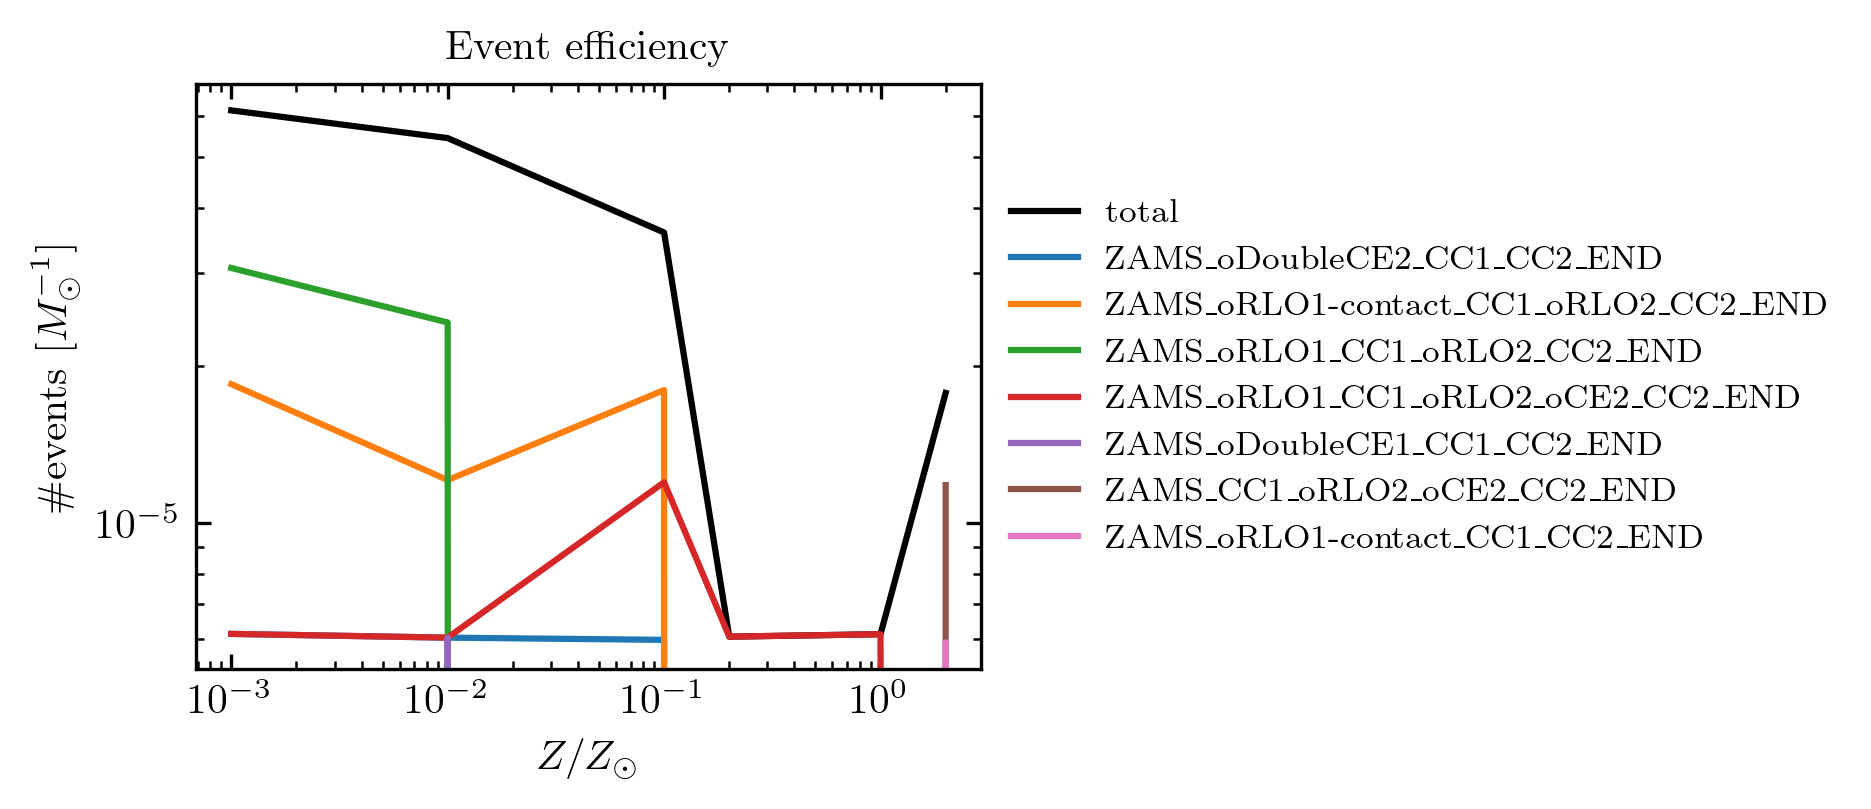

In [21]:
BBH_mergers.plot_efficiency_over_metallicity(model_weight_identifier='extended_IMF',
                                             channels = True)


In [ ]:
#BBH_mergers.plot_efficiency_over_metallicity(model_weight_identifier="extended_IMF",
#    channels=True)
#
# Save figure to visualize it
#fig = plt.gcf()
#fig.savefig("efficiency_over_metallicity.png", dpi=300)
#plt.close(fig)

You might also be interested in seeing the evolution of the binary in more detail.

For this, you can plot the TransientPopulation over a grid slice.
For example, below we plot binaries over the $q=0.7$ slice at $Z=10^{-4} Z_\odot$ on the HMS-HMS grid.

If no slice is given, all mass ratios are plotted.

You can also plot a property from the `TransientPopulation.population` DataFrame as a colormap.
And specific formation_channels if they're in the DataFrame.

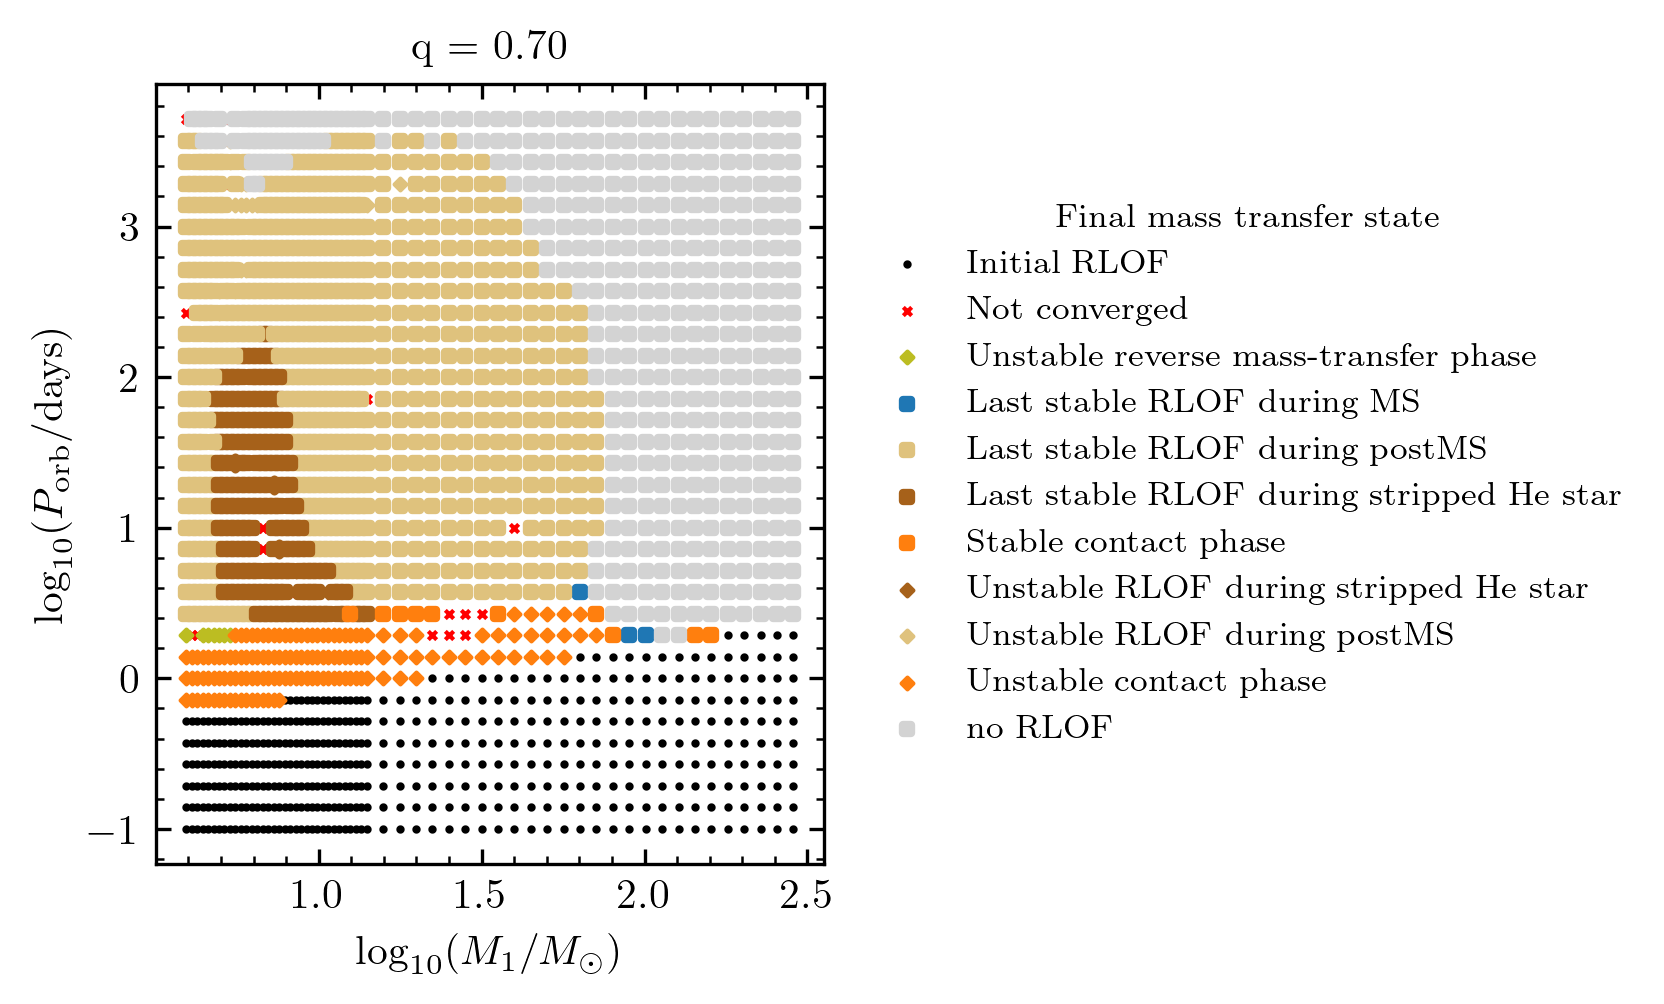

In [22]:
BBH_mergers.plot_popsyn_over_grid_slice('HMS-HMS', 1, slices=[0.7],
                                         save_fig=False)


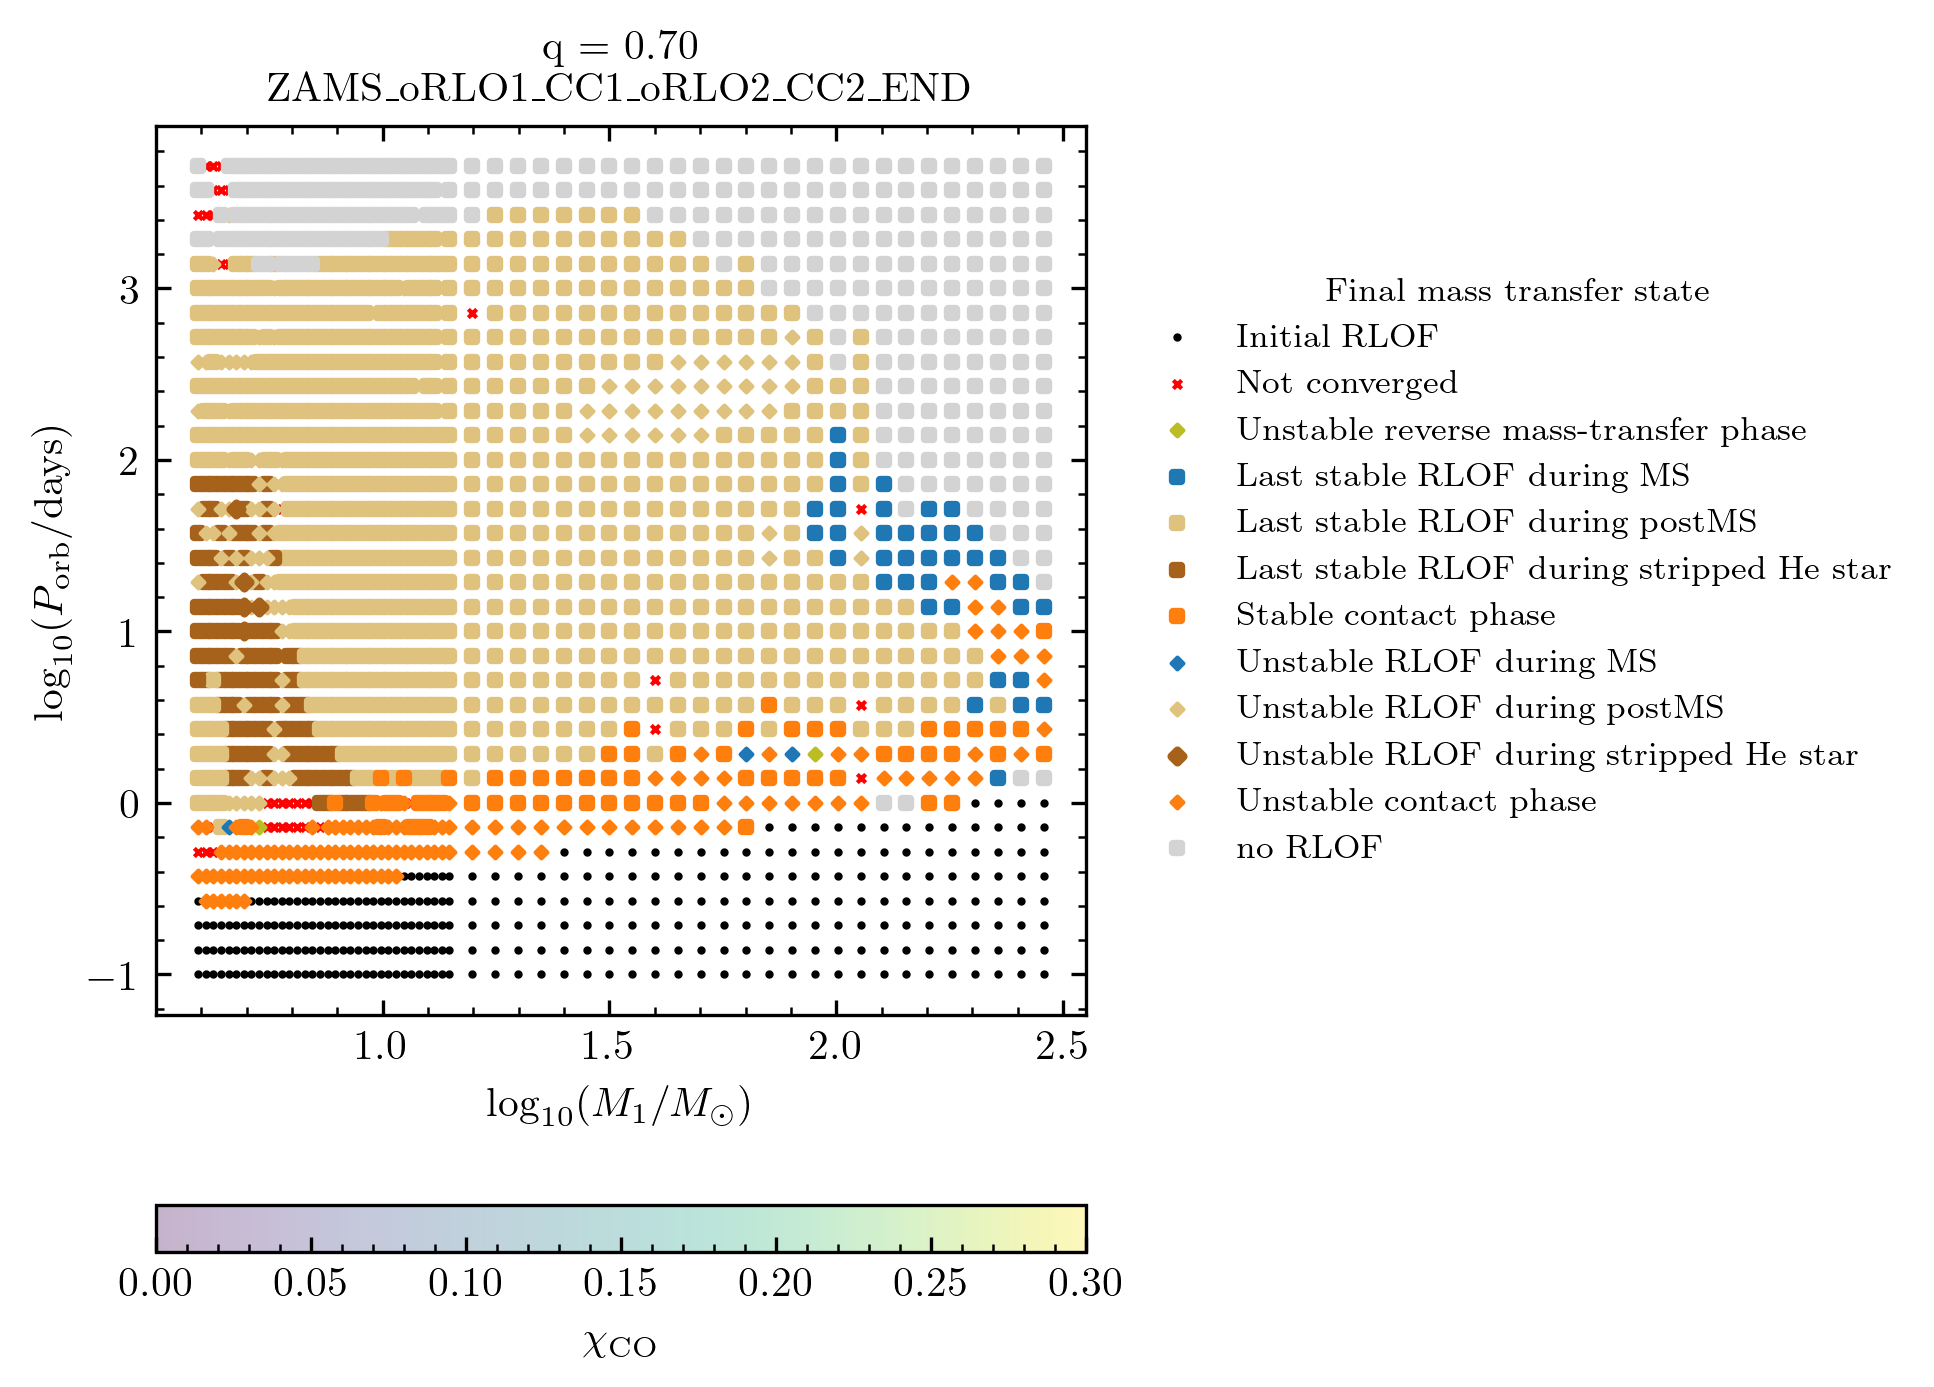

In [25]:
BBH_mergers.plot_popsyn_over_grid_slice('HMS-HMS', 1e-3, slices=[0.7], prop='S1_spin', prop_range=[0,0.3], save_fig=False,
                                         channel='ZAMS_oRLO1_CC1_oRLO2_CC2_END') # SMT channel


### 3. Cosmic rate

- So far these events do not consider the metallicity or star formation rate evolution of the Universe.

POSYDON comes with several built-in star formation histories and metallicity evolutions

In [26]:
BBH_mergers = TransientPopulation(filename='../Generated_Tuto_Data/BBH_contact.h5', transient_name='BBH')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [27]:
MODEL = {
    'delta_t' : 100, # Myr
    'SFR' : 'IllustrisTNG', # Neijssel2019, Madau+Fragos2017
    'sigma_SFR' : None,
}

rates = BBH_mergers.calculate_cosmic_weights('IllustrisTNG', MODEL_in=MODEL,
                                              model_weights='extended_IMF')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/numpy/lib/function_base.py:2455: RuntimeWarning: invalid value encountered in _integral_comoving_distance_z1z2_scalar (vectorized)


In [ ]:
from IPython.display import display

print("Redshift and age of the Universe at the formation of the binaries in the population are :")

print("First 10 entries:")
display(rates.z_birth.head(10))

print("Last 10 entries:")
display(rates.z_birth.tail(10))

Redshift and age of the UNiverse at the formation of the binaries in the population are :
First 10 entries:


,z,t
0,0.003473,13.747616
1,0.010472,13.647616
2,0.017542,13.547616
3,0.024687,13.447616
4,0.031906,13.347616
5,0.039202,13.247616
6,0.046575,13.147616
7,0.054028,13.047616
8,0.061561,12.947616
9,0.069176,12.847616


Last 10 entries:


,z,t
128,5.919830,0.947616
129,6.454037,0.847616
130,7.104501,0.747616
131,7.917918,0.647616
132,8.971372,0.547616
133,10.402985,0.447616
134,12.490545,0.347616
135,15.900718,0.247616
136,22.821039,0.147616
137,49.335426,0.047616


In [51]:
print("Redshift at which an event takes place : ")

print("The first 5 binaries :")
display(rates.z_events.head(5))

print("The last 5 binaries :")
display(rates.z_events.tail(5))


Redshift at which an event takes place : 
The first 5 binaries :


,0,1,2,3,4,5,6,7,8,9,...,128,129,130,131,132,133,134,135,136,137
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.248438,0.258337,0.268370,0.278541,0.288854,0.299311,0.309918,0.320677,0.331592,0.342669
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.133176,1.161995,1.191697,1.222327,1.253936,1.286578,1.320310,1.355194,1.391298,1.428695
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000498,0.007466,...,3.521735,3.699497,3.895571,4.113199,4.356468,4.630607,4.942438,5.301039,5.718795,6.213099
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.398576,0.410681,0.422979,0.435477,0.448180,0.461094,0.474225,0.487581,0.501167,0.514991
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.005439,0.012458,...,3.646217,3.836681,4.047684,4.283040,4.547611,4.847699,5.191641,5.590725,6.060662,6.624053


The last 5 binaries :


,0,1,2,3,4,5,6,7,8,9,...,128,129,130,131,132,133,134,135,136,137
25,NaN,NaN,NaN,0.005881,0.012905,0.020001,0.027171,0.034417,0.041739,0.049139,...,4.868074,5.215135,5.618183,6.093276,6.663572,7.363874,8.249271,9.413048,11.028339,13.461889
26,NaN,NaN,0.002793,0.009785,0.016849,0.023986,0.031198,0.038486,0.045852,0.053296,...,5.055269,5.431851,5.872673,6.397336,7.034733,7.829488,8.854768,10.240475,12.244403,15.472160
27,0.002817,0.009809,0.016873,0.024010,0.031223,0.038511,0.045877,0.053322,0.060847,0.068455,...,5.874300,6.399291,7.037136,7.832529,8.858769,10.246033,12.252781,15.486619,21.863325,43.623147
28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001319,...,3.378125,3.541920,3.721703,3.920146,4.140579,4.387204,4.665414,4.982256,5.347137,5.772929
29,NaN,NaN,NaN,NaN,0.005683,0.012704,0.019798,0.026966,0.034210,0.041530,...,4.557444,4.858908,5.204564,5.605825,6.078593,6.645774,7.341747,8.220840,9.374853,10.973632


In [53]:
print("The weight of the event based on the SFR, its metallicity, and its weight in the population is : ")

print("The first 5 entries :")
display(rates.weights.head(5))

print("The last 5 entries :")
display(rates.weights.tail(5))

The weight of the event based on the SFR, its metallicity, and its weight in the population is : 
The first 5 entries :


,0,1,2,3,4,5,6,7,8,9,...,128,129,130,131,132,133,134,135,136,137
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,...,15.405174,17.992920,14.147044,12.592763,10.274139,6.396507,2.073213,0.077082,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,...,198.840155,223.616276,169.608626,145.898150,115.223590,69.548172,21.886494,0.791199,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000002,0.000360,...,701.263986,792.573586,604.708323,523.783429,417.000172,254.049808,80.809477,2.957503,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,...,36.617602,41.935540,32.364798,28.306626,22.712934,13.918843,4.444082,0.162889,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000189,0.001001,...,721.470782,815.859855,622.860875,539.885525,430.163328,262.309649,83.525346,3.060689,0.0,0.0


The last 5 entries :


,0,1,2,3,4,5,6,7,8,9,...,128,129,130,131,132,133,134,135,136,137
25,0.000000,0.000000,0.000000,0.015635,0.076367,0.184718,0.342370,0.553496,0.821228,1.155132,...,1191.730342,664.108582,369.481469,185.638986,27.359775,1.550535,0.000000,0.0,0.0,0.0
26,0.000000,0.000000,0.000668,0.008212,0.024689,0.051027,0.087165,0.135685,0.194838,0.269671,...,1234.615989,998.365844,717.741006,445.734222,238.949144,88.082706,23.553091,0.0,0.0,0.0
27,0.002354,0.026625,0.077907,0.157931,0.270188,0.409668,0.575090,0.784295,1.036305,1.327272,...,385.848030,175.038618,73.179398,18.158265,0.168108,0.000000,0.000000,0.0,0.0,0.0
28,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000509,...,258.227750,115.746236,47.716970,11.645291,0.105677,0.000000,0.000000,0.0,0.0,0.0
29,0.000000,0.000000,0.000000,0.000000,0.009058,0.045127,0.108434,0.203120,0.331758,0.494845,...,325.976505,146.907381,60.938629,14.977913,0.137041,0.000000,0.000000,0.0,0.0,0.0


You can directly work with the weights and the z_events to get events at specific redshifts.

Or you can calculate the rate density over redshift using the `calculate_intrinsic_rate_density` function.
This will calculate the rate over redshift for you.

You can use the output of the function immediately, or get them from `rates.intrinsic_rate_density`.

In [31]:
from posydon.popsyn.synthetic_population import Rates

rates = Rates(filename='../Generated_Tuto_Data/BBH_contact.h5', transient_name='BBH', SFH_identifier='IllustrisTNG')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [32]:
out = rates.calculate_intrinsic_rate_density(channels=True)

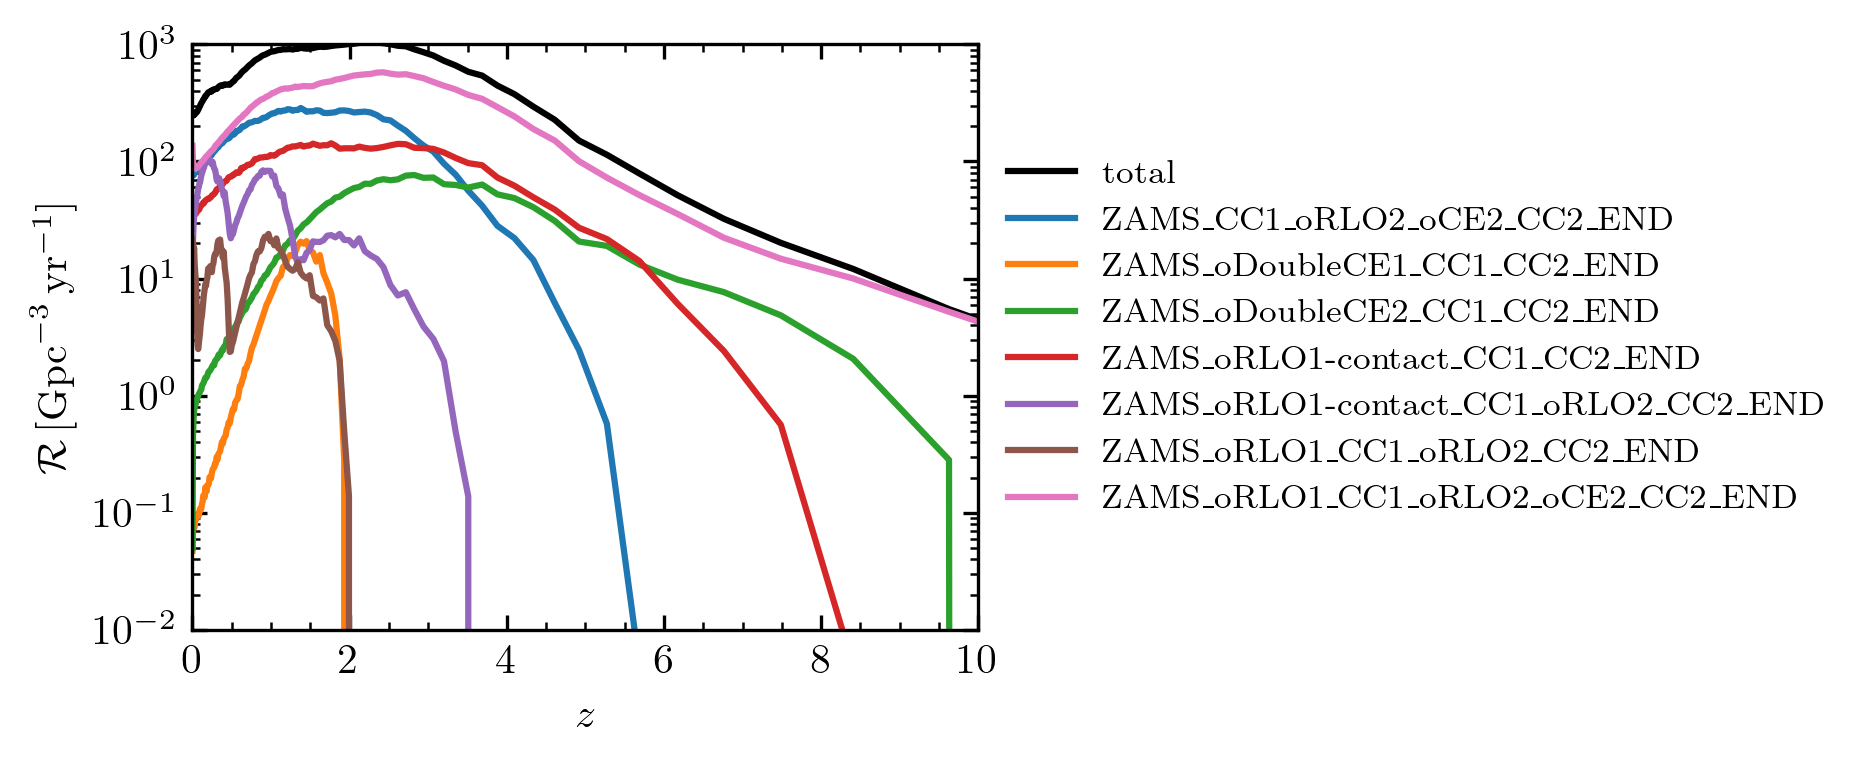

In [33]:
rates.intrinsic_rate_density

rates.plot_intrinsic_rate(channels=True, xlim=(0,10), ylim=(1e-2,1e3))
#fig = plt.gcf()
#fig.savefig("intrinsic_rate_density.png", dpi=300)
#plt.close(fig)

### 4. Properties of the systems

Sometimes you might want some more details about the actual population and its properties.

`plot_hist_properties()` allows you to plot these.

By default, the function will create its own figure and plot it. If you would like more control over the output, you can give it your own pyplot axis and set `show=False`.
This allows you to adapt and change the plot to your liking after finishing adding the properties.

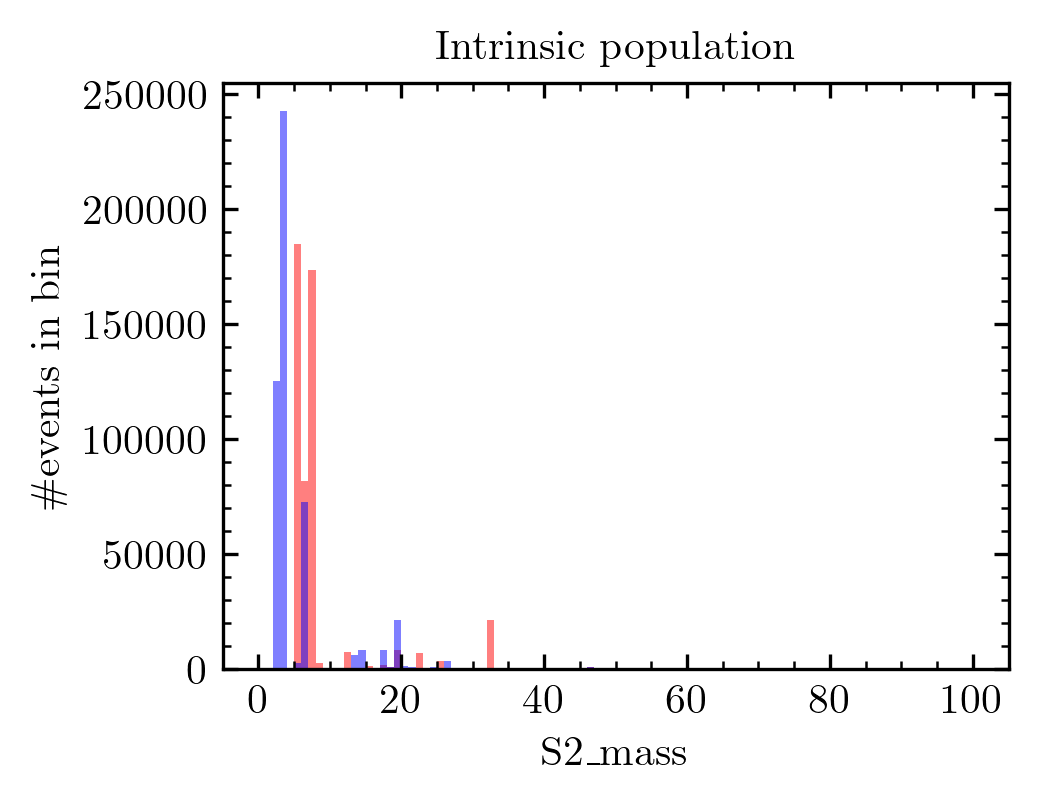

In [34]:
import numpy as np
import matplotlib.pyplot as plt

bins = np.linspace(0,100,101)
fig, ax = plt.subplots(1,1)
rates.plot_hist_properties('S1_mass', intrinsic=True, bins = bins,
                           color = 'red', ax = ax, label = 'S1', show=False)
rates.plot_hist_properties('S2_mass', intrinsic=True, bins = bins,
                           color = 'blue', ax = ax, label = 'S2', show=True)

ax.set_ylabel('Rate density [Gpc$^{-3}$ yr$^{-1}$')
ax.set_xlabel('Mass [M$_\odot$]')
ax.legend()
#fig.savefig("mass_distribution.png", dpi=300)
plt.show()

### 5. Observable population

Sometimes, however, you're not just interested in the intrinsic population, and want an observable population.
This could be a supernova detection fraction for a telescope survey, or the LVK detection efficiency for GW mergers.

You can apply these using `calculate_observable_population`. Similar to the `create_transient_population`, this function takes a `observable_func`, which describes the observability of a transient.

An `observable_func` takes chunks of

1. ```TransientPopulation.population```
2. The `TransientPopulation.z_events`
3. The `TransientPopulation.weights`

Using these, new weights are calculated and stored as a separate observable population of your TransientPopulation.
The BBH analysis framework comes with a detection function for several detector sensitivities and configurations.

In [35]:
from posydon.popsyn.transient_select_funcs import DCO_detectability

In [36]:
def DCO_wrapper(transient_chunk, z_event_chunk, weights_chunk):
    sensitivity = 'design_H1L1V1'
    return DCO_detectability(sensitivity, transient_chunk, z_event_chunk, weights_chunk,
                             verbose=False)

In [37]:
rates.calculate_observable_population(DCO_wrapper, 'design_H1L1V1')

rates.observable_population('design_H1L1V1')

,0,1,2,3,4,5,6,7,8,9,...,128,129,130,131,132,133,134,135,136,137
0,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,14.181205,16.257052,12.700271,11.176662,8.883170,5.447698,1.739427,0.063812,0.0,0.0
1,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,1.285235,0.919528,0.468846,0.257921,0.112694,0.046044,0.009841,0.000069,0.0,0.0
2,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000002,0.000360,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0
3,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,26.723940,29.653583,22.282173,18.718778,14.541231,8.555105,2.648443,0.092409,0.0,0.0
4,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000189,0.001001,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0
5,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,12.089922,10.819263,6.411244,4.317129,3.357731,1.555003,0.360616,0.008914,0.0,0.0
6,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,4.675562,4.517943,2.494352,1.609179,0.864601,0.362606,0.098292,0.006362,0.0,0.0
7,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,12.563902,15.053329,11.072587,9.645477,8.174216,5.512203,2.461347,0.350091,0.0,0.0
8,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,6.532986,6.474289,4.395234,3.321738,2.297061,1.416189,0.554644,0.063008,0.0,0.0
9,1.788013e-07,1.587507e-05,0.000055,0.000122,0.000232,3.475873e-04,0.000551,0.000802,0.001014,0.001328,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0


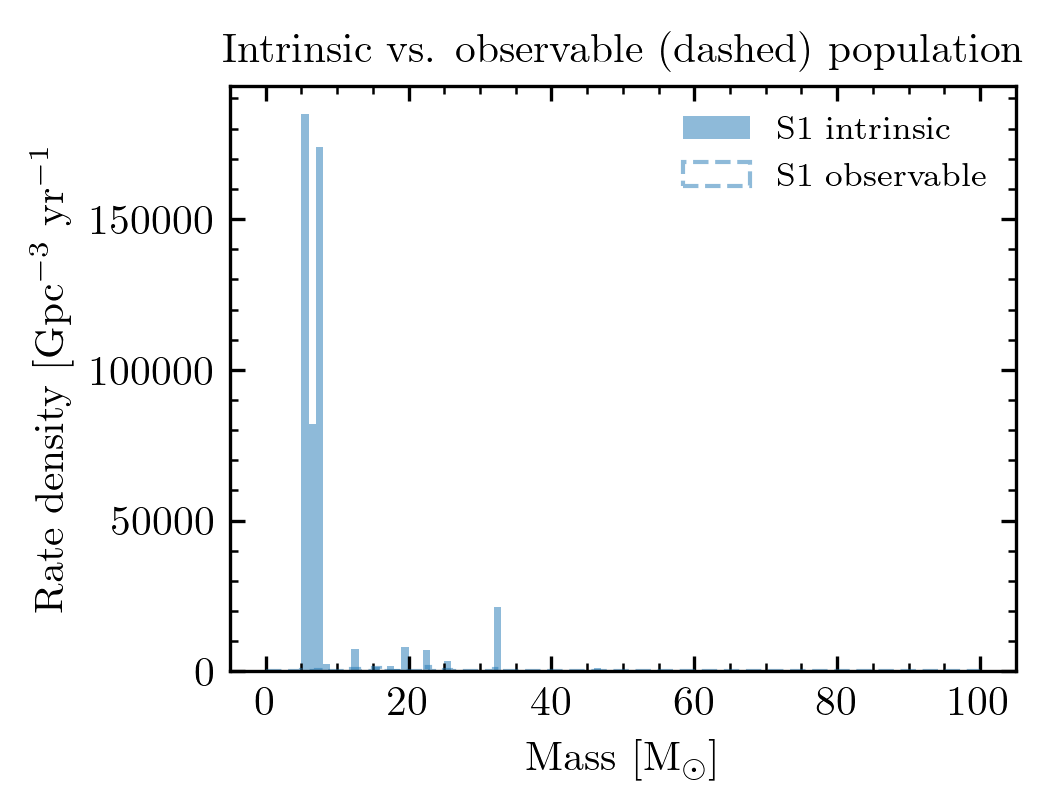

In [38]:
bins = np.linspace(0,100,101)
fig, ax = plt.subplots(1,1)

rates.plot_hist_properties('S1_mass', intrinsic = True, observable = 'design_H1L1V1',
                           bins = bins, ax = ax, label = 'S1', show = False)
ax.set_ylabel('Rate density [Gpc$^{-3}$ yr$^{-1}$')
ax.set_xlabel('Mass [M$_\odot$]')
ax.legend()
#fig.savefig("mass_distribution_observable.png", dpi=300)
plt.show()